In [1]:
import numpy as np
import pandas as pd
from scipy.io import loadmat

long_mat = loadmat("corr-offsite-results_1-12_winter_hour_train60_multi1_th50.mat")
print(long_mat.keys())   
short_mat = loadmat("short_term_cov.mat")
print(short_mat.keys())

dict_keys(['__header__', '__version__', '__globals__', 'allError', 'allError_NWP', 'allError_res', 'allNWPinfo', 'allVariance', 'allY_Fore', 'allY_Fore_res', 'allY_NWP', 'allY_Test', 'allY_int', 'maes', 'maes_nwp', 'maes_res'])
dict_keys(['__header__', '__version__', '__globals__', 'allVariance_Fore', 'allY_Fore', 'maes'])


In [2]:
import numpy as np

loc_idx = [7, 8] ## index for E05/E06
L_total = 9      ##total location for base model
ORDER = 'loc_first'   # flatten order

mu_long = np.asarray(long_mat["allY_Fore"])[:, loc_idx, :] ## pick data for E05/E06
mu_long = np.transpose(mu_long, (2, 1, 0))     ## 183*2*24

mu_short = np.asarray(short_mat["allY_Fore"])[:, loc_idx, :]
mu_short = np.transpose(mu_short, (2, 1, 0))        

y_raw = np.asarray(long_mat["allY_Test"]) ## 24*2*183
y_true = np.transpose(y_raw[:, :, :], (2, 1, 0)) 

D = mu_long.shape[0]  ## 183
L = 2

## flatten the data
if ORDER == 'hour_first':
    idx0 = np.array([h * L_total + loc_idx[0] for h in range(24)], dtype=int)
    idx1 = np.array([h * L_total + loc_idx[1] for h in range(24)], dtype=int)
elif ORDER == 'loc_first':
    idx0 = np.array([loc_idx[0] * 24 + h for h in range(24)], dtype=int)  ## 7*24+1-8*24 index for E05
    idx1 = np.array([loc_idx[1] * 24 + h for h in range(24)], dtype=int) ## index for E06
else:
    raise ValueError("ORDER must be 'hour_first' or 'loc_first'.")

# covariance for long term model
Sig_long_raw = np.asarray(long_mat["allVariance"])   # 216*216*183
print(Sig_long_raw.shape)
if Sig_long_raw.ndim == 3 and Sig_long_raw.shape[0] == 24 * L_total:
    # (216,216,183) get covariance matrix by location
    Sig_long = np.empty((D, L, 24, 24))
    for d in range(D):
        S = Sig_long_raw[:, :, d] 
        Sig_long[d, 0] = S[np.ix_(idx0, idx0)]
        Sig_long[d, 1] = S[np.ix_(idx1, idx1)]
elif Sig_long_raw.ndim == 4 and Sig_long_raw.shape[:2] == (24, 24):
    # if raw covariance matrix in other form
    Ssel = Sig_long_raw[:, :, loc_idx, :]
    Sig_long = np.transpose(Ssel, (3, 2, 0, 1))
else:
    raise ValueError(f"Unexpected long covariance shape: {Sig_long_raw.shape}")

# covaraince for the short-term
Sig_short_raw = np.asarray(short_mat["allVariance_Fore"]) 
print(Sig_short_raw.shape)
if Sig_short_raw.ndim == 3 and Sig_short_raw.shape[0] == 24 * L_total:
    Sig_short = np.empty((D, L, 24, 24))
    for d in range(D):
        S = Sig_short_raw[:, :, d]
        Sig_short[d, 0] = S[np.ix_(idx0, idx0)]
        Sig_short[d, 1] = S[np.ix_(idx1, idx1)]
elif Sig_short_raw.ndim == 4 and Sig_short_raw.shape[:2] == (24, 24):
    if Sig_short_raw.shape[2] >= max(loc_idx)+1:
        Ssel = Sig_short_raw[:, :, loc_idx, :]
        Sig_short = np.transpose(Ssel, (3, 2, 0, 1))
    else:
        Sig_short = np.transpose(Sig_short_raw, (2, 0, 1))[:, None, :, :].repeat(2, axis=1)
elif Sig_short_raw.ndim == 2 and Sig_short_raw.shape == (24, 24):
    Sig_short = np.tile(Sig_short_raw, (D, 2, 1, 1))
else:
    raise ValueError(f"Unexpected short covariance shape: {Sig_short_raw.shape}")

# final mu and covaraince for the base model
muX, SigXX = mu_short, Sig_short     # (183,2,24), (183,2,24,24)
muY, SigYY = mu_long,  Sig_long      # (183,2,24), (183,2,24,24)

print("muX:", muX.shape, "SigXX:", SigXX.shape)
print("muY:", muY.shape, "SigYY:", SigYY.shape)
print("y_true:", y_true.shape)

# muX:   (183, 2, 24)  SigXX: (183, 2, 24, 24)
# muY:   (183, 2, 24)  SigYY: (183, 2, 24, 24)
# y_true:(183, 2, 24)


(216, 216, 183)
(216, 216, 183)
muX: (183, 2, 24) SigXX: (183, 2, 24, 24)
muY: (183, 2, 24) SigYY: (183, 2, 24, 24)
y_true: (183, 2, 24)


In [7]:
ens = loadmat('ensemble_es_constrain.mat')
ens_ind = loadmat('ensemble_es_constrain_independence.mat')
ens_uni = loadmat('ensemble_es_constrain_univariate.mat')
ens_uni_ind = loadmat('ensemble_es_constrain_univariate_ind.mat')

In [28]:
Sig_long = long_mat['allVariance']

In [29]:
Sig_short = short_mat['allVariance_Fore']

In [30]:
import numpy as np
def pick_std(Sigma_full):
    H = 24
    R = Sigma_full.shape[2]
    locs_use = [8, 9]
    
    std_out = np.zeros((H, len(locs_use), R))
    
    for r in range(R):
        for j, loc in enumerate(locs_use):
            start = (loc - 1) * H
            end   = loc * H
            block = Sigma_full[start:end, start:end, r]   # 24×24
            std_out[:, j, r] = np.sqrt(np.diag(block))
    return std_out


In [31]:
sig_short = pick_std(Sig_short)[:,:,45:]
sig_long = pick_std(Sig_long)[:,:,45:]

In [32]:
Sig_ens = ens['Sigma']
Sig_ens_ind = ens_ind['Sigma']
Sig_ens_uni = ens_uni_ind['Sigma']

In [33]:
def sigma_from_cov(Sigma):
    var = np.diagonal(Sigma, axis1=1, axis2=2)   # (n_roll, n_loc, 24)
    sigma = np.sqrt(np.maximum(var, 1e-12))
    sigma = np.transpose(sigma, (2, 0, 1))       # -> (24, n_loc, n_roll)
    return sigma

In [34]:
sig_cross = sigma_from_cov(Sig_ens)
sig_ind = sigma_from_cov(Sig_ens_ind)
sig_uni = sigma_from_cov(Sig_ens_uni)

In [35]:
sig_cross.shape

(24, 2, 138)

In [36]:
def crps_roll_from_mu_sigma(mu, sig, y, h_start, h_end):
    """
    mu, sig, y: shape (24, n_loc, n_roll)
    h_start, h_end: Python slicing, e.g. 0,6 for 1-6 hours
    return: shape (n_roll,)
    """
    crps_all = gaussian_crps(mu, sig, y)             # (24, n_loc, n_roll)
    sub = crps_all[h_start:h_end, :, :]              # (H_block, n_loc, n_roll)
    return np.mean(sub, axis=(0, 1))                 # average over horizon and loc

In [37]:
import numpy as np
import pandas as pd
from scipy.stats import norm

def gaussian_crps(mu, sig, y):
    sig = np.maximum(sig, 1e-10)
    z = (y - mu) / sig
    return sig * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))

def crps_roll_from_mu_sigma(mu, sig, y, h_start, h_end):
    crps_all = gaussian_crps(mu, sig, y)
    sub = crps_all[h_start:h_end, :, :]
    return np.mean(sub, axis=(0, 1))

def summarize_crps_regimes(
    mu_short, sig_short,
    mu_long, sig_long,
    mu_ind, sig_ind,
    mu_cross, sig_cross,
    y_true
):
    out = {'roll': np.arange(mu_short.shape[2])}

    blocks = {
        '1_6': (0, 6),
        '7_24': (6, 24),
        '1_24': (0, 24),
    }

    for name, (a, b) in blocks.items():
        c_short = crps_roll_from_mu_sigma(mu_short, sig_short, y_true, a, b)
        c_long  = crps_roll_from_mu_sigma(mu_long,  sig_long,  y_true, a, b)
        c_ind   = crps_roll_from_mu_sigma(mu_ind,   sig_ind,   y_true, a, b)
        c_cross = crps_roll_from_mu_sigma(mu_cross, sig_cross, y_true, a, b)

        out[f'crps_short_{name}'] = c_short
        out[f'crps_long_{name}'] = c_long
        out[f'crps_ind_{name}'] = c_ind
        out[f'crps_cross_{name}'] = c_cross

        # improvement > 0 means cross is better
        out[f'imp_crps_{name}'] = c_ind - c_cross

        # forecasting regime based on base models
        out[f'regime_crps_{name}'] = np.where(c_short < c_long, 'short_better', 'long_better')

        combined = np.concatenate([c_short, c_long])
        q_shared = np.quantile(combined, 0.75)

        print(len(c_short))
        print(c_short.mean(), c_short.std())
        print(c_long.mean(), c_long.std())
        print(f"{name} shared threshold (75th percentile): {q_shared}")

        difficulty = np.full(len(c_short), 'mixed', dtype=object)

        difficulty[(c_short > q_shared) & (c_long > q_shared)] = 'both_bad'

        difficulty[(c_short <= q_shared) & (c_long <= q_shared)] = 'both_good'

        out[f'difficulty_crps_{name}'] = difficulty

    return pd.DataFrame(out)

In [41]:
import numpy as np
import pandas as pd
from scipy.stats import norm

def gaussian_crps(mu, sig, y):
    sig = np.maximum(sig, 1e-10)
    z = (y - mu) / sig
    return sig * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))

def crps_roll_from_mu_sigma(mu, sig, y, h_start, h_end):
    crps_all = gaussian_crps(mu, sig, y)
    sub = crps_all[h_start:h_end, :, :]
    return np.mean(sub, axis=(0, 1))

def summarize_crps_regimes_hybrid(
    mu_short, sig_short,
    mu_long, sig_long,
    mu_ind, sig_ind,
    mu_cross, sig_cross,
    y_true,
    per_baselines  
):
    out = {'roll': np.arange(mu_short.shape[2])}

    blocks = {
        '1_6': (0, 6),
        '7_24': (6, 24),
        '1_24': (0, 24),
    }

    for name, (a, b) in blocks.items():

        c_short = crps_roll_from_mu_sigma(mu_short, sig_short, y_true, a, b)
        c_long  = crps_roll_from_mu_sigma(mu_long,  sig_long,  y_true, a, b)
        c_ind   = crps_roll_from_mu_sigma(mu_ind,   sig_ind,   y_true, a, b)
        c_cross = crps_roll_from_mu_sigma(mu_cross, sig_cross, y_true, a, b)

        out[f'crps_short_{name}'] = c_short
        out[f'crps_long_{name}'] = c_long
        out[f'crps_ind_{name}'] = c_ind
        out[f'crps_cross_{name}'] = c_cross

        out[f'imp_crps_{name}'] = c_ind - c_cross

        base_crps = per_baselines[name]
        
        crpss_short = 1 - (c_short / base_crps)
        crpss_long  = 1 - (c_long / base_crps)

        out[f'regime_{name}'] = np.where(crpss_short > crpss_long, 'short_better', 'long_better')

        combined_crpss = np.concatenate([crpss_short, crpss_long])
        q_shared_skill = np.quantile(combined_crpss, 0.25)

        difficulty = np.full(len(c_short), 'mixed', dtype=object)

        # both_bad
        difficulty[(crpss_short < q_shared_skill) & (crpss_long < q_shared_skill)] = 'both_bad'

        # both_good
        difficulty[(crpss_short >= q_shared_skill) & (crpss_long >= q_shared_skill)] = 'both_good'

        out[f'difficulty_{name}'] = difficulty

    return pd.DataFrame(out)

In [43]:
mu_short = short_mat['allY_Fore'][:,[7,8],45:]
mu_long = long_mat['allY_Fore'][:,[7,8],45:]
mu_uni = ens_uni['mu']
mu_cross = ens['mu']

In [44]:
true = long_mat['allY_Test'][:,:,45:]

In [46]:
per_baselines = {
    '1_6': 1.709,
    '7_24': 3.830,
    '1_24': 3.204
}

In [47]:
df_crps = summarize_crps_regimes_hybrid(
    mu_short[:,:,:], sig_short[:,:,:],
    mu_long[:,:,:], sig_long[:,:,:],
    mu_uni[:,:,:], sig_uni[:,:,:],
    mu_cross[:,:,:], sig_cross[:,:,:],
    true,
    per_baselines=per_baselines
)

In [48]:
for block in ['1_6', '7_24', '1_24']:
    print(f'\n=== {block} ===')
    print(
        df_crps[f'difficulty_{block}']
        .value_counts()
        .reindex(['both_good', 'mixed', 'both_bad'], fill_value=0)
    )


=== 1_6 ===
difficulty_1_6
both_good    93
mixed        21
both_bad     24
Name: count, dtype: int64

=== 7_24 ===
difficulty_7_24
both_good    94
mixed        19
both_bad     25
Name: count, dtype: int64

=== 1_24 ===
difficulty_1_24
both_good    97
mixed        13
both_bad     28
Name: count, dtype: int64


In [50]:
data_good = df_crps.loc[df_crps['difficulty_1_6'] == 'both_good', 'crps_cross_1_6']
data_mix  = df_crps.loc[df_crps['difficulty_1_6'] == 'mixed', 'crps_cross_1_6']
data_bad  = df_crps.loc[df_crps['difficulty_1_6'] == 'both_bad', 'crps_cross_1_6']
data_good.mean(), data_mix.mean(), data_bad.mean()

(0.7595199214951293, 1.0838012283650325, 1.7962651285752977)

In [149]:
c_short = crps_roll_from_mu_sigma(mu_short, sig_short, true, 1, 24)
c_long  = crps_roll_from_mu_sigma(mu_long,  sig_long,  true, 1, 24)

In [246]:
df_crps.describe()

,roll,crps_short_1_6,crps_long_1_6,crps_ind_1_6,crps_cross_1_6,imp_crps_1_6,crps_short_7_24,crps_long_7_24,crps_ind_7_24,crps_cross_7_24,imp_crps_7_24,crps_short_1_24,crps_long_1_24,crps_ind_1_24,crps_cross_1_24,imp_crps_1_24
count,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000
mean,19.500000,0.957382,1.138028,0.946541,0.942509,0.004032,1.198783,1.172516,1.168000,1.164320,0.003680,1.138433,1.163894,1.112635,1.108867,0.003768
std,11.690452,0.378524,0.514995,0.433198,0.403947,0.035286,0.466928,0.451726,0.480523,0.467377,0.021249,0.374943,0.378297,0.398638,0.384249,0.021368
min,0.000000,0.509296,0.593905,0.434184,0.474156,-0.056258,0.601779,0.593205,0.574952,0.594271,-0.032393,0.627778,0.624964,0.582018,0.589862,-0.033709
25%,9.750000,0.667900,0.710484,0.610303,0.640180,-0.021466,0.818117,0.805835,0.787193,0.798758,-0.010178,0.875231,0.949722,0.838330,0.847606,-0.012032
50%,19.500000,0.893040,0.989656,0.849023,0.847006,-0.002368,1.069026,1.031937,1.036955,1.034065,-0.000793,1.071210,1.028662,1.027404,1.008889,0.002806
75%,29.250000,1.040140,1.472331,1.134940,1.116927,0.018442,1.512767,1.368738,1.419049,1.407753,0.013070,1.357002,1.376723,1.305414,1.314555,0.012282
max,39.000000,2.045638,2.901155,2.227972,2.188670,0.122363,2.311948,2.393201,2.464198,2.449128,0.075059,2.084757,2.242854,2.271924,2.185039,0.086885


In [53]:
## figure 5 in the paper
## other methods 
long = loadmat("corr-offsite-results_1-12_winter_hour_train60_multi1_th50.mat")
short = loadmat("short_term_cov.mat")
#arimax = loadmat("arimaX_24roll_30day.mat")
per = loadmat("PER_all.mat")
NWP = loadmat("NWP.mat")
#ens1 = loadmat("benchmark1.mat")
ens_linear = loadmat("ensemble_test_linear.mat")
ens_es = loadmat("ensemble_es_constrain.mat")

In [56]:
l1 = loadmat('R1_airu_train60_multi1_th50.mat')
s1 = loadmat('R1_test_results_hour_train10_multi1_th90.mat')

In [57]:
s1['allVariance'][:,:,-D:].shape

(216, 216, 138)

In [58]:
Siga = l1['allVariance'][:,:,-D:]
R = Siga.shape[2]
Sigma_loc = np.zeros((2, 24, 24, R))
Sigma_loc[0, :, :, :] = Siga[0:24, 0:24, :]
Sigma_loc[1, :, :, :] = Siga[24:48, 24:48, :]


In [59]:
Sia = s1['allVariance'][7*24:9*24, 7*24:9*24,-D:]
Ra = Sia.shape[2]
Sigma_locs = np.zeros((2, 24, 24, Ra))
Sigma_locs[0, :, :, :] = Sia[0:24, 0:24, :]
Sigma_locs[1, :, :, :] = Sia[24:48, 24:48, :]

In [60]:
Sigma_locs.shape

(2, 24, 24, 138)

In [63]:
import numpy as np

CUT_FIRST_DAYS = 45     # 45 calibration days
L_TOTAL        = 9      # total site (different methods may have different )
ORDER_216      = 'loc_first'  # 
LOC_LIST_SUB   = [7, 8] # index for E05/E06
LOC_G_EVAL     = 7      # index to evaluate 

S_SCENARIOS    = 1000   
SEED           = 123
RNG            = np.random.default_rng(SEED)

SEGMENTS = {"1-6": slice(0,6), "7-24": slice(6,24), "1-24": slice(0,24)}

def as_24_2_D(a):
    ## organize to 24,2,D
    a = np.asarray(a).squeeze()
    if a.ndim != 3:
        raise ValueError(f"expect 3D, got {a.shape}")
    if a.shape[0] == 24 and a.shape[1] == 2:
        return a
    if a.shape[2] == 24 and a.shape[1] == 2:  # (D,2,24) -> (24,2,D)
        return np.transpose(a, (2,1,0))
    if a.shape[0] == 2 and a.shape[1] == 24:  # (2,24,D) -> (24,2,D)
        return np.transpose(a, (1,0,2))
    raise ValueError(f"cannot normalize to (24,2,D), got {a.shape}")

def idx_of_loc(loc_global, L_total=9, order='loc_first'):
    if order == 'loc_first':
        return np.array([loc_global*24 + h for h in range(24)], dtype=int)
    else:  # 'hour_first'
        return np.array([h*L_total + loc_global for h in range(24)], dtype=int)

def pick_column_from_subpair(arr_24_2_D, loc_global, loc_list_pair):
    pos = loc_list_pair.index(loc_global) ## pick the site in the global list
    return arr_24_2_D[:, pos, :]

def sigma_loc_24_24_D(Sigma, loc_global, *, L_total=9, order='loc_first',
                      loc_list_for_sigma=None):
    ## get covariance 24,24,D 
    Sig = np.asarray(Sigma)
    if Sig.ndim == 3 and Sig.shape[:2] == (24,24):
        return Sig
    if Sig.ndim == 3 and Sig.shape[0] == Sig.shape[1] == 24*L_total:
        D = Sig.shape[2]
        idx = idx_of_loc(loc_global, L_total=L_total, order=order)
        return Sig[np.ix_(idx, idx, np.arange(D))]  # (24,24,D)
    if Sig.ndim == 4 and Sig.shape[1:3] == (24,24):
        if loc_list_for_sigma is None:
            raise ValueError("Need loc_list_for_sigma for (n,24,24,D) Sigma.")
        pos = loc_list_for_sigma.index(loc_global)
        return Sig[pos]  # (24,24,D)
    raise ValueError(f"Unsupported Sigma shape {Sig.shape}")

def cholesky_psd(A, I=None):
    if I is None: I = np.eye(A.shape[0])
    jitter = 1e-6
    for _ in range(8):
        try:
            return np.linalg.cholesky(A + jitter * I)
        except np.linalg.LinAlgError:
            jitter *= 10.0
    evals, Q = np.linalg.eigh((A + A.T)/2.0)
    evals = np.clip(evals, 1e-9, None)
    Apsd = (Q * evals) @ Q.T
    return np.linalg.cholesky(Apsd)

def gen_scenarios_gaussian(mu_24, Sig_24_24, S, rng):
    L = cholesky_psd(Sig_24_24)
    Z = rng.standard_normal((S, 24))
    return mu_24[None, :] + Z @ L.T  # (S,24)

def energy_score(y, X, M_pairs=10000, rng=None):
    S = X.shape[0]
    term1 = np.linalg.norm(X - y[None,:], axis=1).mean()
    if rng is None: rng = np.random.default_rng(0)
    i = rng.integers(0, S, size=M_pairs)
    j = rng.integers(0, S, size=M_pairs)
    m = (i != j)
    diffs = X[i[m]] - X[j[m]]
    term2 = 0.5 * np.linalg.norm(diffs, axis=1).mean()
    return float(term1 - term2)

def variogram_score(y, X, p=0.5):
    H = X.shape[1]
    iu, ju = np.triu_indices(H, k=1)
    ydiff = np.abs(y[iu] - y[ju]) ** p
    Xdiff = np.abs(X[:, iu] - X[:, ju]) ** p
    return float(np.sum((ydiff - Xdiff.mean(axis=0)) ** 2))

def band_coverage(y, X, lo=0.1, hi=0.9):
    qlo = np.quantile(X, lo, axis=0)
    qhi = np.quantile(X, hi, axis=0)
    inside = (y >= qlo) & (y <= qhi)
    return float(inside.mean())

def mae_rmse_of_ensemble_mean(y, X):
    mu = X.mean(axis=0)
    e  = y - mu
    return float(np.mean(np.abs(e))), float(np.sqrt(np.mean(e**2)))


y_true_all = ens_es["y_true"]         
y_true_all = np.asarray(y_true_all)
if y_true_all.ndim != 3:
    raise ValueError("y_true should be 3D (D,2,24) or compatible.")
if y_true_all.shape[0] != 24: 
    y_true_all = np.transpose(y_true_all, (2,1,0))  #  (24,2,D_all)
D_all = y_true_all.shape[2]
y_true = y_true_all[:, :, CUT_FIRST_DAYS:]    
D = y_true.shape[2]

## get 216*216 cov matrix 
Var216_all = np.asarray(long['allVariance'])
if Var216_all.shape[0] != Var216_all.shape[1] or Var216_all.shape[0] != 24*L_TOTAL:
    raise ValueError("long['allVariance'] must be (216,216,D_all) with 9 locations.")
Var216 = Var216_all[:, :, -D:]  

## A is ens
muA_raw    = ens_es.get('mu', None)            
SigmaA_raw = ens_es.get('Sigma', None)        
if muA_raw is None:
    raise ValueError("ens_es['mu'] not found.")
muA_full = as_24_2_D(muA_raw)[:, :, -D:]      

## if Sigma is already 2,24,24,D, use directly, otherwise cut the 216,216 to 24,24
if SigmaA_raw is not None:
    SigmaA_full = np.asarray(SigmaA_raw)[..., -D:]  # 假设形状 (2,24,24,D)
else:
    SigmaA_full = np.stack(
        [sigma_loc_24_24_D(Var216, g, L_total=L_TOTAL, order=ORDER_216) for g in LOC_LIST_SUB],
        axis=0
    )  # (2,24,24,D)

## B is long
if 'allY_Fore' in long:
    muB_full = np.stack([np.asarray(long['allY_Fore'])[:, g, -D:] for g in LOC_LIST_SUB], axis=1)  # (24,2,D)
else:
    raise ValueError("Provide muB (e.g., from long['allY_Fore']).")

SigmaB_full = np.stack(
    [sigma_loc_24_24_D(Var216, g, L_total=L_TOTAL, order=ORDER_216) for g in LOC_LIST_SUB],
    axis=0
)  # (2,24,24,D)
SigmaB_full = Sigma_loc
## C is short
if 'short' in globals() and ('allY_Fore' in short):
    muC_full = np.stack([np.asarray(short['allY_Fore'])[:, g, -D:] for g in LOC_LIST_SUB], axis=1)
    if 'allVariance_Fore' in short:
        Var216_short = np.asarray(short['allVariance_Fore'])[:, :, -D:]
        SigmaC_full = np.stack(
            [sigma_loc_24_24_D(Var216_short, g, L_total=L_TOTAL, order=ORDER_216) for g in LOC_LIST_SUB],
            axis=0
        )
        SigmaC_full = Sigma_locs
    else:
        SigmaC_full = SigmaB_full.copy()
else:
    ## if not provided short
    muC_full    = muA_full.copy()
    SigmaC_full = SigmaA_full.copy()

def eval_model(mu_24_2_D, Sigma_any, y_true_24_2_D, loc_global, *,
               loc_list_pair=None, L_total=9, order='loc_first',
               S=1000, rng=None, segments=None, p_vs=0.5, cov_lo=0.1, cov_hi=0.9):
    """
    mu_24_2_D:   (24,2,D)
    Sigma_any:   (2,24,24,D) or (24,24,D) 或 (216,216,D)
    loc_global:  evaluate index
    loc_list_pair: (24,2,D) corresponds to 
    """
    if rng is None: rng = np.random.default_rng(0)
    if segments is None: segments = SEGMENTS


    mu_loc = pick_column_from_subpair(mu_24_2_D,   loc_global, LOC_LIST_SUB if loc_list_pair is None else loc_list_pair)  # (24,D)
    yt_loc = pick_column_from_subpair(y_true_24_2_D,loc_global, LOC_LIST_SUB if loc_list_pair is None else loc_list_pair)  # (24,D)

    Sig_loc = sigma_loc_24_24_D(Sigma_any, loc_global,
                                L_total=L_total, order=order,
                                loc_list_for_sigma=(LOC_LIST_SUB if (Sigma_any.ndim==4 and Sigma_any.shape[0] in (2, len(LOC_LIST_SUB))) else None))
    D = mu_loc.shape[1]
    assert Sig_loc.shape == (24,24,D)

    metrics = {seg: {"ES": np.empty(D),
                     "VS": np.empty(D),
                     "COV": np.empty(D),
                     "MAEmean": np.empty(D),
                     "RMSEmean": np.empty(D)} for seg in segments.keys()}

    for d in range(D):
        mu_d = mu_loc[:, d]
        y_d  = yt_loc[:, d]
        Sig_d= Sig_loc[:, :, d]

        X = gen_scenarios_gaussian(mu_d, Sig_d, S, rng)  # (S,24)

        for name, sl in segments.items():
            Xs, ys = X[:, sl], y_d[sl]
            metrics[name]["ES"][d]       = energy_score(ys, Xs, M_pairs=10000, rng=rng)
            metrics[name]["VS"][d]       = variogram_score(ys, Xs, p=p_vs)
            metrics[name]["COV"][d]      = band_coverage(ys, Xs, lo=cov_lo, hi=cov_hi)
            mae_m, rmse_m                = mae_rmse_of_ensemble_mean(ys, Xs)
            metrics[name]["MAEmean"][d]  = mae_m
            metrics[name]["RMSEmean"][d] = rmse_m

    return metrics

def summarize(metrics, name):
    print(f"\n== {name} ==")
    for seg in ["1-6", "7-24", "1-24"]:
        ES  = metrics[seg]["ES"].mean()
        VS  = metrics[seg]["VS"].mean()
        CV  = metrics[seg]["COV"].mean()
        MAE = metrics[seg]["MAEmean"].mean()
        RM  = metrics[seg]["RMSEmean"].mean()
        print(f"{seg:>4s} | ES={ES:.4f}  VS={VS:.4f}  COV80={CV:.3f}  MAEμ={MAE:.3f}  RMSEμ={RM:.3f}")

metrics_A = eval_model(muA_full, SigmaA_full, y_true, LOC_G_EVAL,
                       loc_list_pair=LOC_LIST_SUB, L_total=L_TOTAL, order=ORDER_216,
                       S=S_SCENARIOS, rng=RNG, segments=SEGMENTS)

metrics_B = eval_model(muB_full, SigmaB_full, y_true, LOC_G_EVAL,
                       loc_list_pair=LOC_LIST_SUB, L_total=L_TOTAL, order=ORDER_216,
                       S=S_SCENARIOS, rng=RNG, segments=SEGMENTS)

metrics_C = eval_model(muC_full, SigmaC_full, y_true, LOC_G_EVAL,
                       loc_list_pair=LOC_LIST_SUB, L_total=L_TOTAL, order=ORDER_216,
                       S=S_SCENARIOS, rng=RNG, segments=SEGMENTS)

summarize(metrics_A, "Model A")
summarize(metrics_B, "Model B")
summarize(metrics_C, "Model C")



== Model A ==
 1-6 | ES=2.9237  VS=6.3797  COV80=0.835  MAEμ=1.353  RMSEμ=1.607
7-24 | ES=5.7837  VS=58.7776  COV80=0.795  MAEμ=1.509  RMSEμ=1.854
1-24 | ES=6.6141  VS=103.6073  COV80=0.805  MAEμ=1.470  RMSEμ=1.847

== Model B ==
 1-6 | ES=3.3712  VS=6.2531  COV80=0.791  MAEμ=1.551  RMSEμ=1.868
7-24 | ES=5.7761  VS=56.6942  COV80=0.824  MAEμ=1.519  RMSEμ=1.862
1-24 | ES=6.8522  VS=104.0886  COV80=0.816  MAEμ=1.527  RMSEμ=1.921

== Model C ==
 1-6 | ES=2.9451  VS=5.7280  COV80=0.843  MAEμ=1.371  RMSEμ=1.629
7-24 | ES=6.0288  VS=61.9797  COV80=0.811  MAEμ=1.556  RMSEμ=1.923
1-24 | ES=6.8570  VS=108.7310  COV80=0.819  MAEμ=1.510  RMSEμ=1.910


In [64]:
def std_to_cov_diag(std_24_2_D):

    std = np.asarray(std_24_2_D)
    if std.shape[0] != 24 or std.shape[1] != 2:
        raise ValueError(f"std_to_cov_diag expects (24,2,D), got {std.shape}")
    var = std**2  # (24,2,D)
    D = var.shape[2]
    Sig = np.zeros((2, 24, 24, D), dtype=float)
    for k in range(2):
        for d in range(D):
            Sig[k, :, :, d] = np.diag(var[:, k, d])
    return Sig

In [65]:
# D for NWP
SEED = 123
RNG            = np.random.default_rng(SEED)
muN_raw = NWP.get('NWP', None)
if muN_raw is None:
    raise ValueError("NWP['NWP'] not found.")
muN_raw = np.asarray(muN_raw)

if muN_raw.ndim != 3:
    raise ValueError(f"NWP['NWP'] must be 3D, got {muN_raw.shape}")
if muN_raw.shape[0] == 24:
    muN_all = muN_raw
elif muN_raw.shape[2] == 24:
    muN_all = np.transpose(muN_raw, (2, 1, 0))
else:
    raise ValueError(f"Cannot normalize NWP['NWP'] to (24,L,D), got {muN_raw.shape}")

L_NWP = muN_all.shape[1]

if L_NWP == 2:
    LOC_LIST_NWP = [7, 8]                 
    muN_full = muN_all[:, :, -D:]      
else:
    LOC_LIST_NWP = LOC_LIST_SUB
    if max(LOC_LIST_NWP) >= L_NWP:
        raise ValueError(f"NWP has only {L_NWP} locations but tried to index {LOC_LIST_NWP}.")
    muN_full = np.stack([muN_all[:, g, -D:] for g in LOC_LIST_NWP], axis=1)  # (24,2,D)

std_raw = NWP.get('sigma_nwp', None)
if std_raw is None:
    raise ValueError("NWP['sigma_nwp'] not found.")
std_raw = np.asarray(std_raw)

if std_raw.ndim != 3:
    raise ValueError(f"NWP['sigma_nwp'] must be 3D, got {std_raw.shape}")
if std_raw.shape[0] == 24:
    std_all = std_raw
elif std_raw.shape[2] == 24:
    std_all = np.transpose(std_raw, (2, 1, 0))
else:
    raise ValueError(f"Cannot normalize sigma_nwp to (24,L,D), got {std_raw.shape}")

if std_all.shape[1] == 2:
    stdN_full = std_all[:, :, -D:]        
else:
    if max(LOC_LIST_NWP) >= std_all.shape[1]:
        raise ValueError(f"NWP std has only {std_all.shape[1]} locations but tried to index {LOC_LIST_NWP}.")
    stdN_full = np.stack([std_all[:, g, -D:] for g in LOC_LIST_NWP], axis=1)

# generate cov matrix for NWP, here use diagnal matrix
SigmaN_full = std_to_cov_diag(stdN_full)
# SigmaN_full = std_to_cov_ar1(stdN_full, rho=0.7)

if LOC_G_EVAL not in LOC_LIST_NWP:
    raise ValueError(f"LOC_G_EVAL={LOC_G_EVAL} not in {LOC_LIST_NWP} 中。"
                     "reset")

metrics_N = eval_model(muN_full, SigmaN_full, y_true, LOC_G_EVAL,
                       loc_list_pair=LOC_LIST_NWP,  
                       L_total=L_TOTAL, order=ORDER_216,
                       S=S_SCENARIOS, rng=RNG, segments=SEGMENTS)
summarize(metrics_N, "Model NWP")



== Model NWP ==
 1-6 | ES=3.5466  VS=7.9840  COV80=0.779  MAEμ=1.608  RMSEμ=1.951
7-24 | ES=6.1844  VS=66.6374  COV80=0.771  MAEμ=1.577  RMSEμ=1.966
1-24 | ES=7.3024  VS=121.3808  COV80=0.773  MAEμ=1.585  RMSEμ=2.031


In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

d = 133
day_start = d
day_end = d
seg_name = "1-24"
loc_global = 7
loc_list_pair = (7, 8)
loc_list_pair_NWP = [7, 8]
full_start_datetime = datetime(2020, 1, 30, 1, 0, 0)
cut_first_days = 45
L_total = 9
order = "loc_first"
S_draw = 200
seed = 2024
clip_below_zero = True
residual_type = "mean"   # 你原来传的是 mean

rng = np.random.default_rng(seed)
sl = SEGMENTS[seg_name]

yt_loc = pick_column_from_subpair(y_true, loc_global, loc_list_pair)

muA_loc = pick_column_from_subpair(muA_full, loc_global, loc_list_pair)
muB_loc = pick_column_from_subpair(muB_full, loc_global, loc_list_pair)
muC_loc = pick_column_from_subpair(muC_full, loc_global, loc_list_pair)
muN_loc = pick_column_from_subpair(muN_full, loc_global, loc_list_pair_NWP)

SigA_loc = sigma_loc_24_24_D(
    SigmaA_full, loc_global,
    L_total=L_total, order=order,
    loc_list_for_sigma=loc_list_pair if SigmaA_full.ndim == 4 else None
)
SigB_loc = sigma_loc_24_24_D(
    SigmaB_full, loc_global,
    L_total=L_total, order=order,
    loc_list_for_sigma=loc_list_pair if SigmaB_full.ndim == 4 else None
)
SigC_loc = sigma_loc_24_24_D(
    SigmaC_full, loc_global,
    L_total=L_total, order=order,
    loc_list_for_sigma=loc_list_pair if SigmaC_full.ndim == 4 else None
)
SigN_loc = sigma_loc_24_24_D(
    SigmaN_full, loc_global,
    L_total=L_total, order=order,
    loc_list_for_sigma=loc_list_pair_NWP if SigmaN_full.ndim == 4 else None
)

t_cut = full_start_datetime + timedelta(hours=24 * cut_first_days)

time_concat = []
for dd in range(day_start, day_end + 1):
    base = t_cut + timedelta(hours=24 * dd)
    time_concat.extend([base + timedelta(hours=h) for h in range(sl.start, sl.stop)])

y_obs_concat = yt_loc[sl, day_start:day_end + 1].T.reshape(-1)   # shape = (T,)
T = len(y_obs_concat)

partsA, partsB, partsC, partsN = [], [], [], []

for dd in range(day_start, day_end + 1):
    muA_d_seg = muA_loc[sl, dd]
    muB_d_seg = muB_loc[sl, dd]
    muC_d_seg = muC_loc[sl, dd]
    muN_d_seg = muN_loc[sl, dd]

    SigA_d_sub = SigA_loc[sl, sl, dd]
    SigB_d_sub = SigB_loc[sl, sl, dd]
    SigC_d_sub = SigC_loc[sl, sl, dd]
    SigN_d_sub = SigN_loc[sl, sl, dd]

    try:
        XA_d = gen_scenarios_gaussian(muA_d_seg, SigA_d_sub, S_draw, rng, clip_below_zero)
        XB_d = gen_scenarios_gaussian(muB_d_seg, SigB_d_sub, S_draw, rng, clip_below_zero)
        XC_d = gen_scenarios_gaussian(muC_d_seg, SigC_d_sub, S_draw, rng, clip_below_zero)
        XN_d = gen_scenarios_gaussian(muN_d_seg, SigN_d_sub, S_draw, rng, clip_below_zero)
    except TypeError:
        XA_d = gen_scenarios_gaussian(muA_d_seg, SigA_d_sub, S_draw, rng)
        XB_d = gen_scenarios_gaussian(muB_d_seg, SigB_d_sub, S_draw, rng)
        XC_d = gen_scenarios_gaussian(muC_d_seg, SigC_d_sub, S_draw, rng)
        XN_d = gen_scenarios_gaussian(muN_d_seg, SigN_d_sub, S_draw, rng)

        if clip_below_zero:
            XA_d = np.clip(XA_d, 0, None)
            XB_d = np.clip(XB_d, 0, None)
            XC_d = np.clip(XC_d, 0, None)
            XN_d = np.clip(XN_d, 0, None)

    partsA.append(XA_d)
    partsB.append(XB_d)
    partsC.append(XC_d)
    partsN.append(XN_d)

XA = np.concatenate(partsA, axis=1)   # shape = (S_draw, T)
XB = np.concatenate(partsB, axis=1)
XC = np.concatenate(partsC, axis=1)
XN = np.concatenate(partsN, axis=1)

model_data = {
    "MHP-ENS": XA,
    "LTM": XB,
    "STM": XC,
    "NWP": XN,
}

In [67]:
results = []

for model_name, X in model_data.items():
    S = X.shape[0]
    term1 = np.mean(np.linalg.norm(X - y_obs_concat[None, :], axis=1))

    pairwise_diff = X[:, None, :] - X[None, :, :]
    pairwise_dist = np.linalg.norm(pairwise_diff, axis=2)   # shape (S, S)
    term2 = 0.5 * np.mean(pairwise_dist)

    energy_score = term1 - term2

    crps_t = []
    for t in range(T):
        x_t = X[:, t]                 # shape (S,)
        y_t = y_obs_concat[t]

        term1_t = np.mean(np.abs(x_t - y_t))
        term2_t = 0.5 * np.mean(np.abs(x_t[:, None] - x_t[None, :]))
        crps_t.append(term1_t - term2_t)

    crps_t = np.array(crps_t)
    crps_mean = crps_t.mean()

    if residual_type == "mean":
        pred_center = X.mean(axis=0)
    else:
        pred_center = np.median(X, axis=0)

    resid_center = y_obs_concat - pred_center   
    resid_all_scenarios = y_obs_concat[None, :] - X   

    results.append({
        "model": model_name,
        "EnergyScore_period": energy_score,
        "CRPS_mean_period": crps_mean,
        "RMSE_center": np.sqrt(np.mean(resid_center**2)),
        "MAE_center": np.mean(np.abs(resid_center)),
        "Bias_center": np.mean(resid_center),
    })

results_df = pd.DataFrame(results).sort_values("EnergyScore_period")
print(results_df)

     model  EnergyScore_period  CRPS_mean_period  RMSE_center  MAE_center  \
0  MHP-ENS            2.968332          0.484760     0.702779    0.553162   
1      LTM            3.319577          0.547507     0.712718    0.533605   
2      STM            3.585278          0.592682     0.909818    0.815000   
3      NWP            3.841310          0.651655     1.025382    0.962902   

   Bias_center  
0     0.150877  
1    -0.220890  
2     0.560303  
3     0.677291  


In [68]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.legend_handler import HandlerBase
from scipy.stats import gaussian_kde
from datetime import datetime, timedelta


# =========================================================
# custom legend handler for residual panel:
# line through a small box
# =========================================================
class HandlerPatchLine(HandlerBase):
    def create_artists(
        self, legend, orig_handle,
        xdescent, ydescent, width, height, fontsize, trans
    ):
        patch_proto, line_proto = orig_handle

        rect_w = width * 0.6
        rect_h = height * 0.80
        rect_x = xdescent + (width - rect_w) / 2
        rect_y = ydescent + (height - rect_h) / 2

        rect = Rectangle(
            (rect_x, rect_y),
            rect_w,
            rect_h,
            facecolor=patch_proto.get_facecolor(),
            edgecolor='none',
            alpha=patch_proto.get_alpha(),
            transform=trans
        )

        line_y = rect_y + rect_h / 2
        line = Line2D(
            [xdescent, xdescent + width],
            [line_y, line_y],
            color=line_proto.get_color(),
            linewidth=line_proto.get_linewidth(),
            linestyle=line_proto.get_linestyle(),
            transform=trans
        )

        return [rect, line]


def scenario_roughness_index(X, root=True):
    """
    Scenario roughness based on the second-order finite difference.

    X: array with shape (S, T)
       S = number of generated scenarios
       T = number of time points

    Definition:
        R2 = mean_{s,t} (X_{s,t} - 2 X_{s,t-1} + X_{s,t-2})^2

    If root=True, return sqrt(R2), so the value has the same unit as X.

    Smaller values indicate smoother scenario trajectories.
    """

    X = np.asarray(X)

    if X.ndim != 2:
        raise ValueError("X must be a 2D array with shape (n_scenarios, n_time_steps).")

    if X.shape[1] < 3:
        return np.nan

    second_diff = X[:, 2:] - 2 * X[:, 1:-1] + X[:, :-2]

    roughness = np.mean(second_diff ** 2)

    if root:
        roughness = np.sqrt(roughness)

    return roughness


def plot_scenarios_with_residual_distribution_fanchart(
    muA_full, SigmaA_full,
    muB_full, SigmaB_full,
    muC_full, SigmaC_full,
    y_true,
    muN_full, SigmaN_full, loc_list_pair_NWP,
    loc_global=7,
    loc_list_pair=(7, 8),
    day_start=0, day_end=0,
    seg_name="1-24",
    full_start_datetime=datetime(2020, 1, 30, 1, 0, 0),
    cut_first_days=45,
    L_total=9,
    order="loc_first",
    S_draw=200,
    seed=2024,
    clip_below_zero=True,
    residual_type="median",      # "median" or "mean"
    show_scenarios=True,
    n_scenarios_show=20,
    show_metrics_text=True,
    show_avg_piwidth=True,
    show_coverage=True,
    show_energy_score=True,
    show_roughness=True,
    fan_levels=(5, 10, 20, 30, 40),
    figsize=(16, 14),
    model_colors=None,
    # ===== residual panel controls =====
    add_residual_panel=True,
    residual_bw=0.25,
    residual_hist_alpha=0.28,
    residual_hist_model="MHP-ENS",   # which model gets histogram
    residual_xlabel="Residuals",
    residual_ylabel="Density",
    residual_zero_line=True,
    residual_legend_loc="upper right",
    save_path=None,
):
    """
    Combined figure:
    - top 4 panels: scenario + fan chart
    - bottom 1 panel: residual density plot with legend inside the plot

    Metrics shown in the top panels:
    - Energy Score: multivariate probabilistic forecast accuracy
    - Scenario Roughness: temporal smoothness of generated scenario trajectories

    Scenario Roughness is defined as the root mean squared first difference:
        sqrt(mean((X[:, 1:] - X[:, :-1])^2))

    Smaller roughness indicates smoother scenario trajectories.
    """

    assert 0 <= day_start <= day_end < y_true.shape[2], "day range out of bounds"
    assert residual_type in ("median", "mean"), "residual_type must be 'median' or 'mean'"

    rng = np.random.default_rng(seed)
    sl = SEGMENTS[seg_name]

    if model_colors is None:
        model_colors = {
            "MHP-ENS": "steelblue",
            "LTM": "seagreen",
            "STM": "darkorange",
            "NWP": "slategray",
        }

    # -----------------------------
    # 1) Extract selected location
    # -----------------------------
    yt_loc = pick_column_from_subpair(y_true, loc_global, loc_list_pair)

    muA_loc = pick_column_from_subpair(muA_full, loc_global, loc_list_pair)
    muB_loc = pick_column_from_subpair(muB_full, loc_global, loc_list_pair)
    muC_loc = pick_column_from_subpair(muC_full, loc_global, loc_list_pair)
    muN_loc = pick_column_from_subpair(muN_full, loc_global, loc_list_pair_NWP)

    SigA_loc = sigma_loc_24_24_D(
        SigmaA_full, loc_global,
        L_total=L_total, order=order,
        loc_list_for_sigma=loc_list_pair if SigmaA_full.ndim == 4 else None
    )
    SigB_loc = sigma_loc_24_24_D(
        SigmaB_full, loc_global,
        L_total=L_total, order=order,
        loc_list_for_sigma=loc_list_pair if SigmaB_full.ndim == 4 else None
    )
    SigC_loc = sigma_loc_24_24_D(
        SigmaC_full, loc_global,
        L_total=L_total, order=order,
        loc_list_for_sigma=loc_list_pair if SigmaC_full.ndim == 4 else None
    )
    SigN_loc = sigma_loc_24_24_D(
        SigmaN_full, loc_global,
        L_total=L_total, order=order,
        loc_list_for_sigma=loc_list_pair_NWP if SigmaN_full.ndim == 4 else None
    )

    t_cut = full_start_datetime + timedelta(hours=24 * cut_first_days)

    time_concat = []
    for d in range(day_start, day_end + 1):
        base = t_cut + timedelta(hours=24 * d)
        time_concat.extend([base + timedelta(hours=h) for h in range(sl.start, sl.stop)])

    y_obs_concat = yt_loc[sl, day_start:day_end + 1].T.reshape(-1)

    def gen_concat(mu_loc, Sig_loc):
        parts = []
        for d in range(day_start, day_end + 1):
            mu_d_seg = mu_loc[sl, d]
            Sig_d_sub = Sig_loc[sl, sl, d]

            try:
                Xd = gen_scenarios_gaussian(
                    mu_d_seg,
                    Sig_d_sub,
                    S_draw,
                    rng,
                    clip_below_zero
                )
            except TypeError:
                Xd = gen_scenarios_gaussian(
                    mu_d_seg,
                    Sig_d_sub,
                    S_draw,
                    rng
                )
                if clip_below_zero:
                    Xd = np.clip(Xd, 0, None)

            parts.append(Xd)

        return np.concatenate(parts, axis=1)

    XA = gen_concat(muA_loc, SigA_loc)
    XB = gen_concat(muB_loc, SigB_loc)
    XC = gen_concat(muC_loc, SigC_loc)
    XN = gen_concat(muN_loc, SigN_loc)

    model_data = [
        ("MHP-ENS", XA),
        ("LTM", XB),
        ("STM", XC),
        ("NWP", XN),
    ]

    processed = []
    q_levels = sorted(set(list(fan_levels) + [50] + [100 - q for q in fan_levels]))

    for title, X in model_data:
        qvals = np.percentile(X, q_levels, axis=0)
        qdict = {q: qvals[i] for i, q in enumerate(q_levels)}

        q50 = qdict[50]
        mean_pred = X.mean(axis=0)

        pred_center = q50 if residual_type == "median" else mean_pred
        resid = y_obs_concat - pred_center

        if 5 in qdict and 95 in qdict:
            q_low_main = qdict[5]
            q_high_main = qdict[95]
            main_label = "90% PI"
        else:
            qmin = min(fan_levels)
            q_low_main = qdict[qmin]
            q_high_main = qdict[100 - qmin]
            main_label = f"{100 - 2*qmin}% PI"

        pi_width_t = q_high_main - q_low_main
        avg_pi_width = np.mean(pi_width_t)
        coverage_main = np.mean((y_obs_concat >= q_low_main) & (y_obs_concat <= q_high_main))

        mae = np.mean(np.abs(resid))
        rmse = np.sqrt(np.mean(resid ** 2))
        center_offset = np.mean(np.abs(y_obs_concat - q50) / (pi_width_t + 1e-8))

        # -----------------------------
        # Energy Score
        # -----------------------------
        term1_es = np.mean(np.linalg.norm(X - y_obs_concat[None, :], axis=1))
        pairwise_dist = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
        term2_es = 0.5 * np.mean(pairwise_dist)
        energy_score = term1_es - term2_es

        # -----------------------------
        # Scenario Roughness Index
        # -----------------------------
        roughness = scenario_roughness_index(X)

        processed.append({
            "title": title,
            "X": X,
            "qdict": qdict,
            "pred_center": pred_center,
            "resid": resid,
            "mae": mae,
            "rmse": rmse,
            "avg_pi_width": avg_pi_width,
            "coverage_main": coverage_main,
            "pi_width_t": pi_width_t,
            "center_offset": center_offset,
            "main_label": main_label,
            "energy_score": energy_score,
            "roughness": roughness,
        })

    # -----------------------------
    # figure layout: 5 full-width rows
    # -----------------------------
    nrows = 5 if add_residual_panel else 4
    height_ratios = [1, 1, 1, 1, 0.9] if add_residual_panel else [1, 1, 1, 1]

    fig = plt.figure(figsize=figsize)
    outer_gs = fig.add_gridspec(
        nrows=nrows,
        ncols=1,
        hspace=0.22,
        height_ratios=height_ratios
    )

    # -----------------------------
    # top 4 scenario panels
    # -----------------------------
    top_axes = []

    for i, item in enumerate(processed):
        title = item["title"]
        X = item["X"]
        qdict = item["qdict"]
        pred_center = item["pred_center"]

        ax = fig.add_subplot(outer_gs[i, 0])
        top_axes.append(ax)

        model_color = model_colors.get(title, "steelblue")

        ax.set_ylim(0, 20)
        ax.set_yticks([0, 5, 10, 15, 20])

        if show_scenarios:
            n_show = min(n_scenarios_show, X.shape[0])
            idx_show = rng.choice(X.shape[0], size=n_show, replace=False)

            for s in idx_show:
                ax.plot(
                    time_concat,
                    X[s],
                    linewidth=1.6,
                    alpha=0.2,
                    color="gray",
                    zorder=1
                )

            ax.plot(
                [],
                [],
                color="gray",
                linewidth=0.8,
                alpha=1,
                label="Scenarios"
            )

        fan_pairs = [(q, 100 - q) for q in sorted(fan_levels)]
        fan_alphas = np.linspace(0.10, 0.40, len(fan_pairs))

        for (ql, qu), alpha in zip(fan_pairs, fan_alphas):
            ax.fill_between(
                time_concat,
                qdict[ql],
                qdict[qu],
                color=model_color,
                alpha=alpha,
                linewidth=0,
                zorder=2
            )

        if residual_type == "median":
            ax.plot(
                time_concat,
                qdict[50],
                color=model_color,
                linewidth=2.0,
                label="Median",
                zorder=4
            )
        else:
            ax.plot(
                time_concat,
                pred_center,
                color=model_color,
                linewidth=2.0,
                label="Mean",
                zorder=4
            )

        ax.scatter(
            time_concat,
            y_obs_concat,
            s=42,
            color="maroon",
            marker="*",
            label="Observations",
            zorder=5
        )

        # -----------------------------
        # Metrics text box
        # -----------------------------
        metric_lines = []

        if show_energy_score:
            metric_lines.append(f"Energy Score = {item['energy_score']:.2f}")

        if show_roughness:
            metric_lines.append(f"Roughness = {item['roughness']:.2f}")

        if metric_lines:
            ax.text(
                0.985,
                0.05,
                "\n".join(metric_lines),
                transform=ax.transAxes,
                ha="right",
                va="bottom",
                fontsize=10,
                bbox=dict(
                    boxstyle="round,pad=0.28",
                    facecolor="white",
                    alpha=0.82,
                    edgecolor="gray",
                    linewidth=0.5
                ),
                zorder=10
            )

        ax.set_title(title, fontsize=18)
        ax.set_ylabel("Wind Speed (m/s)", fontsize=15)
        ax.grid(True, alpha=0.25)
        ax.tick_params(axis="y", labelsize=13)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            uniq = dict(zip(labels, handles))

            ax.legend(
                uniq.values(),
                uniq.keys(),
                loc="upper left",
                fontsize=12,
                frameon=False,
                ncol=1
            )

        if i < 3 or add_residual_panel:
            ax.tick_params(axis="x", labelbottom=False)

    # -----------------------------
    # residual panel as ONE full-width row
    # legend is placed inside the residual plot
    # -----------------------------
    if add_residual_panel:
        ax_res = fig.add_subplot(outer_gs[4, 0])

        resid_map = {item["title"]: item["X"] for item in processed}

        rA1 = (y_obs_concat[None, :] - resid_map["MHP-ENS"]).ravel()
        rB1 = (y_obs_concat[None, :] - resid_map["LTM"]).ravel()
        rC1 = (y_obs_concat[None, :] - resid_map["STM"]).ravel()
        rN1 = (y_obs_concat[None, :] - resid_map["NWP"]).ravel()

        kde_data = {
            "MHP-ENS": rA1,
            "LTM": rB1,
            "STM": rC1,
            "NWP": rN1
        }

        all_res = np.concatenate([rA1, rB1, rC1, rN1])

        xmin = np.percentile(all_res, 0)
        xmax = np.percentile(all_res, 100)

        x_grid = np.linspace(xmin, xmax, 500)

        hist_arr = kde_data[residual_hist_model]

        iqr = np.percentile(hist_arr, 75) - np.percentile(hist_arr, 25)
        bin_width = 2 * iqr / (len(hist_arr) ** (1 / 3))

        if bin_width <= 0:
            bins = 35
        else:
            bins = int(np.ceil((xmax - xmin) / bin_width))
            bins = max(25, min(bins, 45))

        hist_color = model_colors[residual_hist_model]

        ax_res.hist(
            hist_arr,
            bins=bins,
            range=(xmin, xmax),
            density=True,
            alpha=residual_hist_alpha,
            color=hist_color,
            edgecolor='none'
        )

        for name, arr in kde_data.items():
            kde = gaussian_kde(arr, bw_method=residual_bw)

            ax_res.plot(
                x_grid,
                kde(x_grid),
                linewidth=2.2,
                color=model_colors[name]
            )

        if residual_zero_line:
            ax_res.axvline(
                0,
                color='gray',
                linestyle='--',
                linewidth=1.2
            )

        ax_res.set_xlabel(residual_xlabel, fontsize=18)
        ax_res.set_ylabel(residual_ylabel, fontsize=18)
        ax_res.tick_params(axis='x', labelsize=14)
        ax_res.tick_params(axis='y', labelsize=14)
        ax_res.set_xlim(xmin, xmax)
        ax_res.grid(axis='y', linestyle='--', alpha=0.35)

        # -----------------------------
        # residual legend inside the plot
        # -----------------------------
        mhp_patch = Rectangle(
            (0, 0),
            1,
            1,
            facecolor=hist_color,
            alpha=residual_hist_alpha,
            edgecolor='none'
        )

        mhp_line = Line2D(
            [0],
            [0],
            color=hist_color,
            lw=2.0
        )

        legend_handles = [
            (mhp_patch, mhp_line),
            Line2D([0], [0], color=model_colors["LTM"], lw=2.0),
            Line2D([0], [0], color=model_colors["STM"], lw=2.0),
            Line2D([0], [0], color=model_colors["NWP"], lw=2.0),
        ]

        legend_labels = [
            residual_hist_model,
            "LTM",
            "STM",
            "NWP"
        ]

        ax_res.legend(
            legend_handles,
            legend_labels,
            handler_map={tuple: HandlerPatchLine()},
            loc=residual_legend_loc,
            frameon=True,
            fontsize=14,
            handlelength=2.2,
            handleheight=1.0,
            handletextpad=0.8,
            borderpad=0.8
        )

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=600, bbox_inches='tight')

    plt.show()

    summary = []

    for item in processed:
        summary.append({
            "model": item["title"],
            "rmse": item["rmse"],
            "mae": item["mae"],
            "avg_pi_width": item["avg_pi_width"],
            "coverage": item["coverage_main"],
            "center_offset": item["center_offset"],
            "main_label": item["main_label"],
            "energy_score": item["energy_score"],
            "scenario_roughness": item["roughness"],
        })

    return summary

/var/folders/z4/sfjcxx3s1px_qp22m2z82c9m0000gn/T/ipykernel_53652/394092599.py:566: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


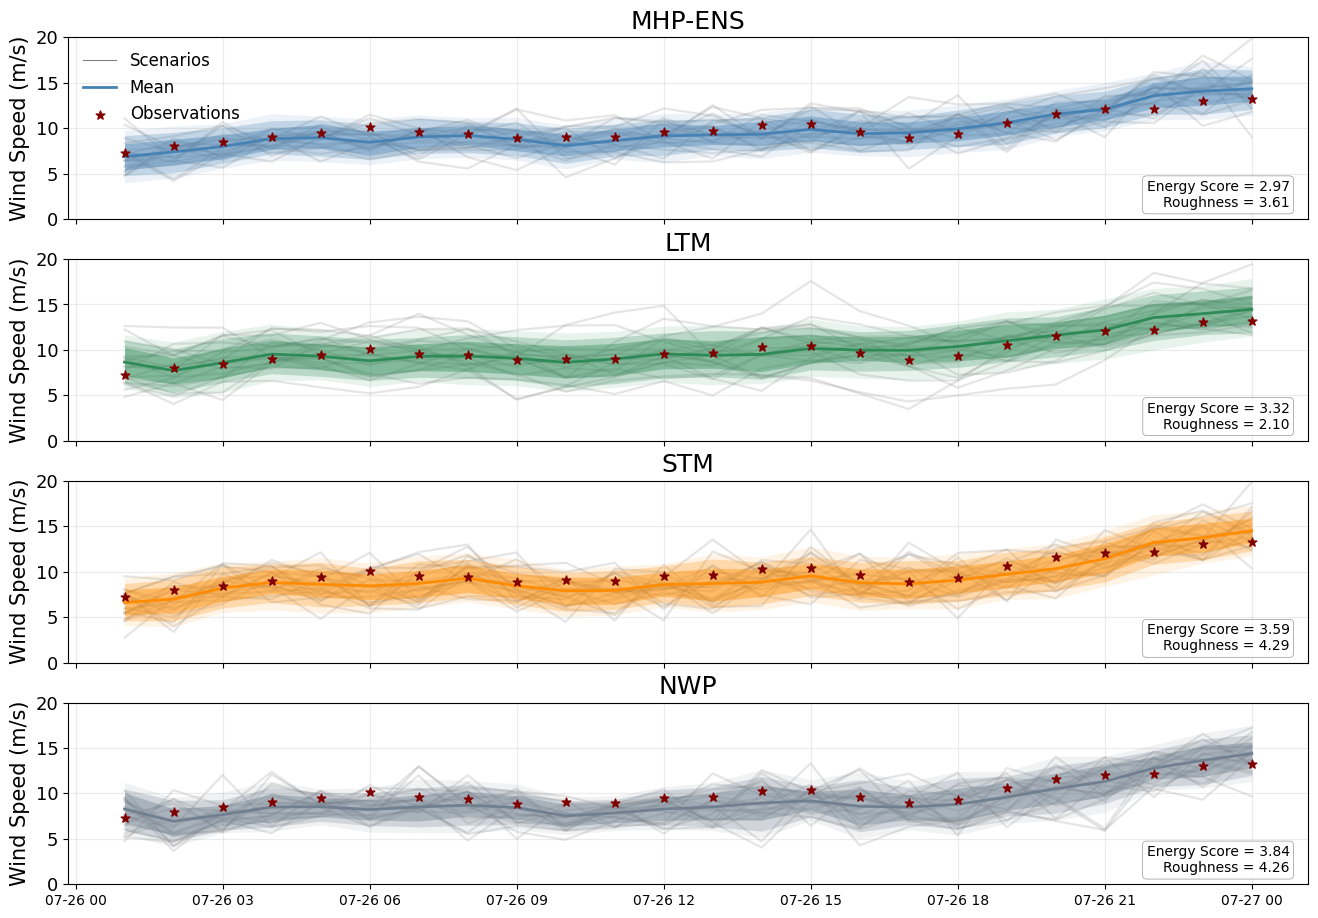

In [69]:
d = 133

summary = plot_scenarios_with_residual_distribution_fanchart(
    muA_full, SigmaA_full,
    muB_full, SigmaB_full,
    muC_full, SigmaC_full,
    y_true,
    muN_full, SigmaN_full, [7, 8],
    loc_global=7,
    loc_list_pair=(7, 8),
    day_start=d,
    day_end=d,
    seg_name="1-24",
    full_start_datetime=datetime(2020, 1, 30, 1, 0, 0),
    cut_first_days=45,
    L_total=9,
    order="loc_first",
    S_draw=200,
    seed=2024,
    clip_below_zero=True,
    residual_type="mean",
    show_scenarios=True,
    n_scenarios_show=20,
    show_metrics_text=False,
    show_avg_piwidth=True,
    show_coverage=True,
    fan_levels=(5, 10, 20),
    figsize=(16, 11),
    add_residual_panel=False,
    residual_bw=0.25,
    residual_hist_alpha=0.28,
    residual_hist_model="MHP-ENS",
    save_path="fig_with_no_panel.png"
)

In [85]:
np.diag(SigmaN_full[0,:,:,0])

array([2.54783309, 1.88259984, 3.46179907, 3.45257038, 2.84469948,
       3.2680057 , 2.49717432, 1.95559277, 3.92998184, 4.18778155,
       5.2004516 , 6.42258752, 3.1557146 , 2.24819613, 2.02915946,
       1.9788871 , 2.57021418, 2.36865797, 1.29055107, 3.52949315,
       5.97234009, 3.74282013, 3.13961418, 4.79523563])